# **OPT-CVNXT-ABL**

In [1]:
import os
import gc
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from pathlib import Path
from PIL import Image
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from optuna.trial import TrialState
from tqdm.auto import tqdm as _tqdm
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_virtual_device_configuration(
        gpus[0],
        [tf.config.experimental.VirtualDeviceConfiguration(memory_limit=8192)]
    )
    print(f'GPU encontrada: {gpus[0].name} (límite: 8 GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite: 8 GB)


-------------
## **Búsqueda de Hiperparámetros**
---------------

In [3]:
# ── Rutas ────────────────────────────────────────────────────────────────────
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset ICBA Folds'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 3' / 'ConvNeXtTiny'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [4]:
# ── Experimento ──────────────────────────────────────────────────────────────
EXPERIMENT_NAME = 'OPT-CVNXT-ABL'
ARQUITECTURA    = 'ConvNeXtTiny'
DATASET         = 'ICBA'

# ── Imagen ───────────────────────────────────────────────────────────────────
IMG_HEIGHT  = 192
IMG_WIDTH   = 352
NUM_CLASSES = 4
CLASSES     = ['Am', 'HTA', 'EAo', 'MCH']

# ── Dataset folds ─────────────────────────────────────────────────────────────
TRAIN_FOLDS = [1, 2, 3, 4]
VAL_FOLD    = 5

# ── Entrenamiento ─────────────────────────────────────────────────────────────
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
BATCH_SIZE    = 16
N_TRIALS      = 20
EPOCH_MAX     = 100
SEED          = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# ── Callbacks ─────────────────────────────────────────────────────────────────
ES_PATIENCE         = 8
ES_MIN_DELTA        = 0.0001
METRIC              = 'val_loss'
DIRECTION           = 'minimize'
N_STARTUP_TRIALS    = 8
N_WARMUP_STEPS      = 10
INTERVAL_STEPS      = 1
N_MIN_TRIALS_PRUNER = 3
RLR_FACTOR          = 0.5
RLR_PATIENCE        = 5
RLR_MIN_DELTA       = 0.0001
RLR_MIN_LR          = 1e-7

# ── LP-FT ─────────────────────────────────────────────────────────────────────
WEIGHT_DECAY = 1e-2
LP_LR        = 1e-3
LP_EPOCHS    = 10

# ── Espacio de búsqueda ───────────────────────────────────────────────────────
FT_BLOCKS_OPTS   = [1, 2]
LR_FT_RANGE      = (1e-6, 1e-4)
DENSE_UNITS_OPTS = [128, 256]

### **Arquitectura**

Estudio de ablación: se parte de los pesos de **ImageNet** (sin preentrenamiento en dataset sintético). El backbone ConvNeXtTiny se carga directamente desde `tf.keras.applications` con `weights='imagenet'`.

El protocolo de entrenamiento es **LP-FT** en dos fases, idéntico al de OPT-CVNXT-FT (Fase 2):
- **Fase LP** (`LP_EPOCHS` épocas): backbone completamente congelado, solo se entrena la cabeza clasificadora con `LP_LR = 1e-3` fijo.
- **Fase FT** (hasta `EPOCH_MAX` épocas con early stopping): se descongelan los últimos bloques de `stage_3` según `ft_blocks`, y se continúa con `learning_rate_ft` buscado por Optuna.

El espacio de búsqueda es idéntico al de Fase 2: `dense_units` ∈ {128, 256}, `ft_blocks` ∈ {1, 2}, `learning_rate_ft` ∈ [1e-6, 1e-4]. Esto permite aislar el efecto del preentrenamiento sintético manteniendo el resto de condiciones constantes.

In [5]:
# ── Bloques a descongelar en fase FT ─────────────────────────────────────────
FINE_TUNE_BLOCKS = {
    1: ['convnext_tiny_stage_3_block_2'],
    2: ['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2'],
}

def set_fine_tune_layers(backbone, ft_blocks):
    prefixes = [b + '_' for b in FINE_TUNE_BLOCKS[ft_blocks]]
    for layer in backbone.layers:
        layer.trainable = any(layer.name.startswith(p) for p in prefixes)

# Verificar nombres reales de capas en stage_3
_tmp = tf.keras.applications.ConvNeXtTiny(
    weights='imagenet', include_top=False,
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)
)
_stage3_names = [l.name for l in _tmp.layers if 'stage_3' in l.name]
del _tmp
tf.keras.backend.clear_session()
gc.collect()

print('Capas de stage_3 disponibles:')
for name in _stage3_names:
    print(f'  {name}')
print()
for n, prefixes in FINE_TUNE_BLOCKS.items():
    print(f'ft_blocks={n}: {prefixes}')

Capas de stage_3 disponibles:
  convnext_tiny_stage_3_block_0_depthwise_conv
  convnext_tiny_stage_3_block_0_layernorm
  convnext_tiny_stage_3_block_0_pointwise_conv_1
  convnext_tiny_stage_3_block_0_gelu
  convnext_tiny_stage_3_block_0_pointwise_conv_2
  convnext_tiny_stage_3_block_0_layer_scale
  convnext_tiny_stage_3_block_0_identity
  convnext_tiny_stage_3_block_1_depthwise_conv
  convnext_tiny_stage_3_block_1_layernorm
  convnext_tiny_stage_3_block_1_pointwise_conv_1
  convnext_tiny_stage_3_block_1_gelu
  convnext_tiny_stage_3_block_1_pointwise_conv_2
  convnext_tiny_stage_3_block_1_layer_scale
  convnext_tiny_stage_3_block_1_identity
  convnext_tiny_stage_3_block_2_depthwise_conv
  convnext_tiny_stage_3_block_2_layernorm
  convnext_tiny_stage_3_block_2_pointwise_conv_1
  convnext_tiny_stage_3_block_2_gelu
  convnext_tiny_stage_3_block_2_pointwise_conv_2
  convnext_tiny_stage_3_block_2_layer_scale
  convnext_tiny_stage_3_block_2_identity

ft_blocks=1: ['convnext_tiny_stage_3_block

In [6]:
def build_convnexttiny_from_imagenet(dense_units, input_shape=(192, 352, 3), num_classes=4):
    base = tf.keras.applications.ConvNeXtTiny(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape,
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=x, name='ConvNeXtTiny_Ablation')
    return model, base


### **Carga de Datos**

Dataset ICBA con folds 1–4 para entrenamiento y fold 5 para validación

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def load_fold_images(fold_dirs, classes):
    X, y = [], []
    for fold_dir in fold_dirs:
        for label_idx, cls in enumerate(classes):
            cls_dir = fold_dir / cls
            if not cls_dir.exists():
                print(f'  Advertencia: {cls_dir} no existe')
                continue
            for f in sorted(cls_dir.iterdir()):
                if f.suffix.lower() in ('.jpg', '.jpeg'):
                    img = np.array(Image.open(f).convert('L'))   # H×W grayscale
                    img = np.stack([img, img, img], axis=-1)     # H×W×3
                    X.append(img)
                    y.append(label_idx)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32)

# ── Cargar datos en memoria ───────────────────────────────────────────────────
print('Cargando datos en memoria...')
train_dirs = [DATA_PATH / 'train' / f'fold {i}' for i in TRAIN_FOLDS]
val_dirs   = [DATA_PATH / 'train' / f'fold {VAL_FOLD}']

X_train, y_train = load_fold_images(train_dirs, CLASSES)
X_val,   y_val   = load_fold_images(val_dirs,   CLASSES)

# Shuffle con seed fija (una sola vez antes de Optuna)
np.random.seed(SEED)
idx     = np.random.permutation(len(X_train))
X_train = X_train[idx]
y_train = y_train[idx]

print(f'\nDatos cargados:')
print(f'  X_train : {X_train.shape}   y_train : {y_train.shape}')
print(f'  X_val   : {X_val.shape}     y_val   : {y_val.shape}')
print(f'\nDistribución de clases:')
header = f"{'Clase':<8}" + f"{'train':>8}" + f"{'val':>8}"
print(header)
print('-' * len(header))
for i, cls in enumerate(CLASSES):
    print(f'{cls:<8}{(y_train == i).sum():>8}{(y_val == i).sum():>8}')
print(f"{'TOTAL':<8}{len(y_train):>8}{len(y_val):>8}")

Cargando datos en memoria...

Datos cargados:
  X_train : (442, 192, 352, 3)   y_train : (442,)
  X_val   : (107, 192, 352, 3)     y_val   : (107,)

Distribución de clases:
Clase      train     val
------------------------
Am           120      29
HTA          114      28
EAo          124      30
MCH           84      20
TOTAL        442     107


### **Estudio de Optuna**

In [8]:
class OptunaPruningCallback(tf.keras.callbacks.Callback):
    def __init__(self, trial, monitor='val_loss'):
        super().__init__()
        self.trial   = trial
        self.monitor = monitor

    def on_epoch_end(self, epoch, logs=None):
        value = logs.get(self.monitor)
        if value is not None:
            self.trial.report(value, epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # ── Hiperparámetros ────────────────────────────────────────────────────────
    dense_units = trial.suggest_categorical('dense_units',      DENSE_UNITS_OPTS)
    ft_blocks   = trial.suggest_categorical('ft_blocks',        FT_BLOCKS_OPTS)
    lr_ft       = trial.suggest_float('learning_rate_ft',       *LR_FT_RANGE, log=True)

    # ── Check anti-duplicados ─────────────────────────────────────────────────
    _existing = next(
        (t for t in trial.study.trials
         if t.state == TrialState.COMPLETE
         and t.number != trial.number
         and t.params == trial.params),
        None
    )
    if _existing is not None:
        print(f'  Trial {trial.number}: duplicado del Trial {_existing.number} → devolviendo val_loss conocido')
        return _existing.value

    # ── Datasets desde arrays en memoria ──────────────────────────────────────
    train_ds = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val))
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    model, base = build_convnexttiny_from_imagenet(
        dense_units,
        input_shape = (IMG_HEIGHT, IMG_WIDTH, 3),
        num_classes = NUM_CLASSES,
    )

    # ── Fase 1: LP — backbone congelado, solo entrena la cabeza ──────────────
    model.compile(
        optimizer = tf.keras.optimizers.AdamW(learning_rate=LP_LR, weight_decay=WEIGHT_DECAY),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )
    model.fit(
        train_ds,
        validation_data = val_ds,
        epochs          = LP_EPOCHS,
        verbose         = 0,
    )

    # ── Fase 2: FT — descongelar bloques seleccionados ────────────────────────
    set_fine_tune_layers(base, ft_blocks)

    model.compile(
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr_ft, weight_decay=WEIGHT_DECAY),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )
    history = model.fit(
        train_ds,
        validation_data = val_ds,
        epochs          = EPOCH_MAX,
        callbacks       = [
            EarlyStopping(
                monitor              = METRIC,
                patience             = ES_PATIENCE,
                min_delta            = ES_MIN_DELTA,
                restore_best_weights = True,
            ),
            ReduceLROnPlateau(
                monitor   = METRIC,
                factor    = RLR_FACTOR,
                patience  = RLR_PATIENCE,
                min_delta = RLR_MIN_DELTA,
                min_lr    = RLR_MIN_LR,
            ),
            OptunaPruningCallback(trial, monitor=METRIC),
        ],
        verbose = 0,
    )

    trial.set_user_attr('epochs_trained', LP_EPOCHS + len(history.history[METRIC]))
    result = min(history.history[METRIC])

    del model, base, train_ds, val_ds, history
    gc.collect()
    tf.keras.backend.clear_session()
    gc.collect()

    return result

In [9]:
_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')

study = optuna.create_study(
    direction      = DIRECTION,
    study_name     = EXPERIMENT_NAME,
    storage        = f'sqlite:///{_db_path}',
    load_if_exists = True,
    sampler        = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_STARTUP_TRIALS),
    pruner         = optuna.pruners.MedianPruner(
        n_startup_trials = N_STARTUP_TRIALS,
        n_warmup_steps   = N_WARMUP_STEPS,
        n_min_trials     = N_MIN_TRIALS_PRUNER,
        interval_steps   = INTERVAL_STEPS,
    ),
)

# ── Limpiar zombies ───────────────────────────────────────────────────────────
_all_trials = study.trials
_zombies = [t for t in _all_trials if t.state == TrialState.RUNNING]
if _zombies:
    for t in _zombies:
        try:
            study._storage.set_trial_state_values(t._trial_id, TrialState.FAIL, {})
        except Exception:
            pass
    _all_trials = study.trials

# ── Reintentar último trial fallido ──────────────────────────────────────────
_failed = [t for t in _all_trials if t.state == TrialState.FAIL and t.params]
if _failed:
    last_failed = max(_failed, key=lambda t: t.number)
    last_done   = max((t.number for t in _all_trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)), default=-1)
    already_completed = any(
        last_failed.params == t.params
        for t in _all_trials
        if t.state == TrialState.COMPLETE
    )
    if last_failed.number > last_done and not already_completed:
        print(f'  Trial {last_failed.number} fallido → reintento')
        study.enqueue_trial(last_failed.params)

# ── Trials restantes ──────────────────────────────────────────────────────────
n_completados = len([t for t in study.trials
                     if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
n_restantes   = max(0, N_TRIALS - n_completados)
print(f'Trials completados: {n_completados} — Trials restantes: {n_restantes}')

# ── Progress bar ──────────────────────────────────────────────────────────────
_pbar = _tqdm(total=N_TRIALS, initial=n_completados, desc='Optuna', unit='trial')

def _trial_callback(study, trial):
    n_done = len([t for t in study.trials
                  if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
    if trial.state == TrialState.COMPLETE:
        _pbar.update(1)
        best = study.best_trial
        _pbar.set_postfix({
            'mejor_trial': best.number,
            'mejor_loss':  f'{best.value:.4f}',
            'ultimo':      f'{trial.value:.4f}',
        })
        print(f'Trial {trial.number:>3} | val_loss={trial.value:.4f} | mejor={best.value:.4f} (t{best.number}) | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.PRUNED:
        _pbar.update(1)
        _pbar.set_postfix({'ultimo': 'podado'})
        print(f'Trial {trial.number:>3} | PODADO | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.FAIL:
        _pbar.set_postfix({'ultimo': 'FAILED'})
        print(f'Trial {trial.number:>3} | FAILED | {n_done}/{N_TRIALS}')

study.optimize(
    objective,
    n_trials          = n_restantes,
    show_progress_bar = False,
    gc_after_trial    = True,
    catch             = (tf.errors.ResourceExhaustedError,),
    callbacks         = [_trial_callback],
)
_pbar.close()

  Trial 10 fallido → reintento
Trials completados: 10 — Trials restantes: 10


Optuna:  50%|#####     | 10/20 [00:00<?, ?trial/s]

Trial  11 | val_loss=0.7210 | mejor=0.6930 (t9) | 11/20
  Trial 12: duplicado del Trial 8 → devolviendo val_loss conocido
Trial  12 | val_loss=0.7034 | mejor=0.6930 (t9) | 12/20
Trial  13 | val_loss=0.7003 | mejor=0.6930 (t9) | 13/20
Trial  14 | val_loss=0.7013 | mejor=0.6930 (t9) | 14/20
Trial  15 | val_loss=0.7124 | mejor=0.6930 (t9) | 15/20
Trial  16 | val_loss=0.6988 | mejor=0.6930 (t9) | 16/20
Trial  17 | val_loss=0.6941 | mejor=0.6930 (t9) | 17/20
Trial  18 | PODADO | 18/20
Trial  19 | val_loss=0.6789 | mejor=0.6789 (t19) | 19/20
Trial  20 | val_loss=0.6626 | mejor=0.6626 (t20) | 20/20


In [10]:
# ── Cargar estudio y guardar CSV ──────────────────────────────────────────────
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)
df_study = study.trials_dataframe()
display(df_study)

df_clean = df_study[df_study['state'].isin(['COMPLETE', 'PRUNED'])].copy()
df_clean = df_clean.reset_index(drop=True)
df_clean.index = df_clean.index + 1
df_clean.index.name = 'trial'

param_cols = sorted([c for c in df_clean.columns if c.startswith('params_')])
cols_order = ['value', 'state', 'datetime_start', 'datetime_complete',
              'duration', 'user_attrs_epochs_trained'] + param_cols
df_clean = df_clean[[c for c in cols_order if c in df_clean.columns]]
df_clean = df_clean.rename(columns={
    'datetime_start':            't_start',
    'datetime_complete':         't_finish',
    'user_attrs_epochs_trained': 'epochs_trained',
    **{c: c.replace('params_', '') for c in param_cols}
})
for col in ['t_start', 't_finish']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].dt.strftime('%d/%m - %H:%M')
if 'duration' in df_clean.columns:
    df_clean['duration'] = df_clean['duration'].apply(
        lambda x: f"{int(x.total_seconds()//3600):02d}:{int((x.total_seconds()%3600)//60):02d}:{int(x.total_seconds()%60):02d}" if pd.notna(x) else ''
    )
df_clean.to_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv')
print(f'CSV guardado: {len(df_clean)} trials')

,number,value,datetime_start,datetime_complete,duration,params_dense_units,params_ft_blocks,params_learning_rate_ft,user_attrs_epochs_trained,system_attrs_fixed_params,state
0,0,0.819761,2026-08-12 12:57:15.612177,2026-08-12 13:09:52.120219,0 days 00:12:36.508042,256,1,0.000002,110.0,NaN,COMPLETE
1,1,0.714823,2026-08-12 13:09:52.668358,2026-08-12 13:15:25.170972,0 days 00:05:32.502614,128,1,0.000026,87.0,NaN,COMPLETE
2,2,0.814765,2026-08-12 13:15:25.764229,2026-08-12 13:21:59.768423,0 days 00:06:34.004194,256,1,0.000002,110.0,NaN,COMPLETE
3,3,0.786901,2026-08-12 13:22:00.304936,2026-08-12 13:28:37.427690,0 days 00:06:37.122754,256,1,0.000004,110.0,NaN,COMPLETE
4,4,0.710010,2026-08-12 13:28:38.165319,2026-08-12 13:36:37.816982,0 days 00:07:59.651663,128,2,0.000008,110.0,NaN,COMPLETE
5,5,0.846078,2026-08-12 13:36:38.567932,2026-08-12 13:44:41.018829,0 days 00:08:02.450897,128,2,0.000001,110.0,NaN,COMPLETE
6,6,0.719270,2026-08-12 13:44:41.936039,2026-08-12 13:47:32.196695,0 days 00:02:50.260656,128,2,0.000085,37.0,NaN,COMPLETE
7,7,0.716323,2026-08-12 13:47:33.057169,2026-08-12 13:55:29.553033,0 days 00:07:56.495864,128,2,0.000008,101.0,NaN,COMPLETE
8,8,0.703420,2026-08-12 13:55:30.569121,2026-08-12 13:59:52.825120,0 days 00:04:22.255999,128,2,0.000025,49.0,NaN,COMPLETE
9,9,0.692991,2026-08-12 13:59:55.088576,2026-08-12 14:04:30.566763,0 days 00:04:35.478187,128,2,0.000029,49.0,NaN,COMPLETE


CSV guardado: 20 trials


In [ ]:
import IPython
print('Reiniciando kernel...')
IPython.Application.instance().kernel.do_shutdown(restart=True)

-------------
## **Resultados**
---------------

In [11]:
# ── Reconstruir contexto post-restart ─────────────────────────────────────────
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from optuna.trial import TrialState
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

REPO_ROOT       = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
MODELS_PATH     = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 3' / 'ConvNeXtTiny'
EXPERIMENT_NAME = 'OPT-CVNXT-ABL'
DIRECTION       = 'minimize'

_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)

n_complete = len([t for t in study.trials if t.state == TrialState.COMPLETE])
n_pruned   = len([t for t in study.trials if t.state == TrialState.PRUNED])
print(f'Trials completos: {n_complete} | Podados: {n_pruned} | Mejor val_loss: {study.best_value:.4f} (trial {study.best_trial.number})')

Trials completos: 19 | Podados: 1 | Mejor val_loss: 0.6626 (trial 20)


### **Evolución del Estudio**

In [12]:
df_trials = pd.read_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv', index_col='trial')

param_cols = [c for c in df_trials.columns if c not in
              ['value', 'state', 't_start', 't_finish', 'duration', 'epochs_trained']]

fmt = {'value': '{:.4f}'}
if 'learning_rate_ft' in df_trials.columns:
    fmt['learning_rate_ft'] = '{:.2e}'

display(df_trials.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,dense_units,ft_blocks,learning_rate_ft
trial,,,,,,,,,
1,0.8198,COMPLETE,12/08 - 12:57,12/08 - 13:09,00:12:36,110.000000,256,1,2.05e-06
2,0.7148,COMPLETE,12/08 - 13:09,12/08 - 13:15,00:05:32,87.000000,128,1,2.61e-05
3,0.8148,COMPLETE,12/08 - 13:15,12/08 - 13:21,00:06:34,110.000000,256,1,2.31e-06
4,0.7869,COMPLETE,12/08 - 13:22,12/08 - 13:28,00:06:37,110.000000,256,1,3.82e-06
5,0.7100,COMPLETE,12/08 - 13:28,12/08 - 13:36,00:07:59,110.000000,128,2,8.17e-06
6,0.8461,COMPLETE,12/08 - 13:36,12/08 - 13:44,00:08:02,110.000000,128,2,1.24e-06
7,0.7193,COMPLETE,12/08 - 13:44,12/08 - 13:47,00:02:50,37.000000,128,2,8.54e-05
8,0.7163,COMPLETE,12/08 - 13:47,12/08 - 13:55,00:07:56,101.000000,128,2,7.59e-06
9,0.7034,COMPLETE,12/08 - 13:55,12/08 - 13:59,00:04:22,49.000000,128,2,2.47e-05


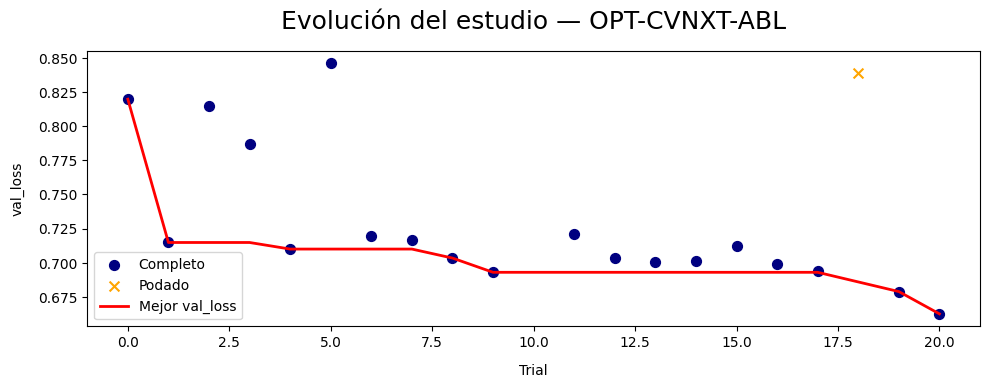

In [13]:
complete = [t for t in study.trials if t.state == TrialState.COMPLETE]
pruned   = [t for t in study.trials if t.state == TrialState.PRUNED]

fig, ax = plt.subplots(figsize=(10, 4))

if complete:
    ax.scatter([t.number for t in complete], [t.value for t in complete],
               color='navy', s=50, label='Completo')

if pruned:
    pruned_y = [list(t.intermediate_values.values())[-1] if t.intermediate_values else None
                for t in pruned]
    ax.scatter([t.number for t in pruned], pruned_y,
               color='orange', s=50, marker='x', label='Podado')

if complete:
    sorted_complete = sorted(complete, key=lambda t: t.number)
    best_so_far = pd.Series([t.value for t in sorted_complete]).cummin()
    ax.plot([t.number for t in sorted_complete], best_so_far,
            color='red', linewidth=2, label='Mejor val_loss')

ax.set_xlabel('Trial', labelpad=10)
ax.set_ylabel('val_loss', labelpad=10)
ax.set_title(f'Evolución del estudio — {EXPERIMENT_NAME}', fontsize=18, y=1.05)
ax.legend()
plt.tight_layout()
plt.show()

### **Análisis por Hiperparámetro**

In [14]:
try:
    import plotly
    fig = optuna.visualization.plot_param_importances(study)
    fig.update_traces(marker_color='navy')
    fig.update_layout(title=f'Importancia de hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado — instalar con: pip install plotly')

/tmp/ipykernel_1178639/2762354712.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(
/tmp/ipykernel_1178639/2762354712.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(


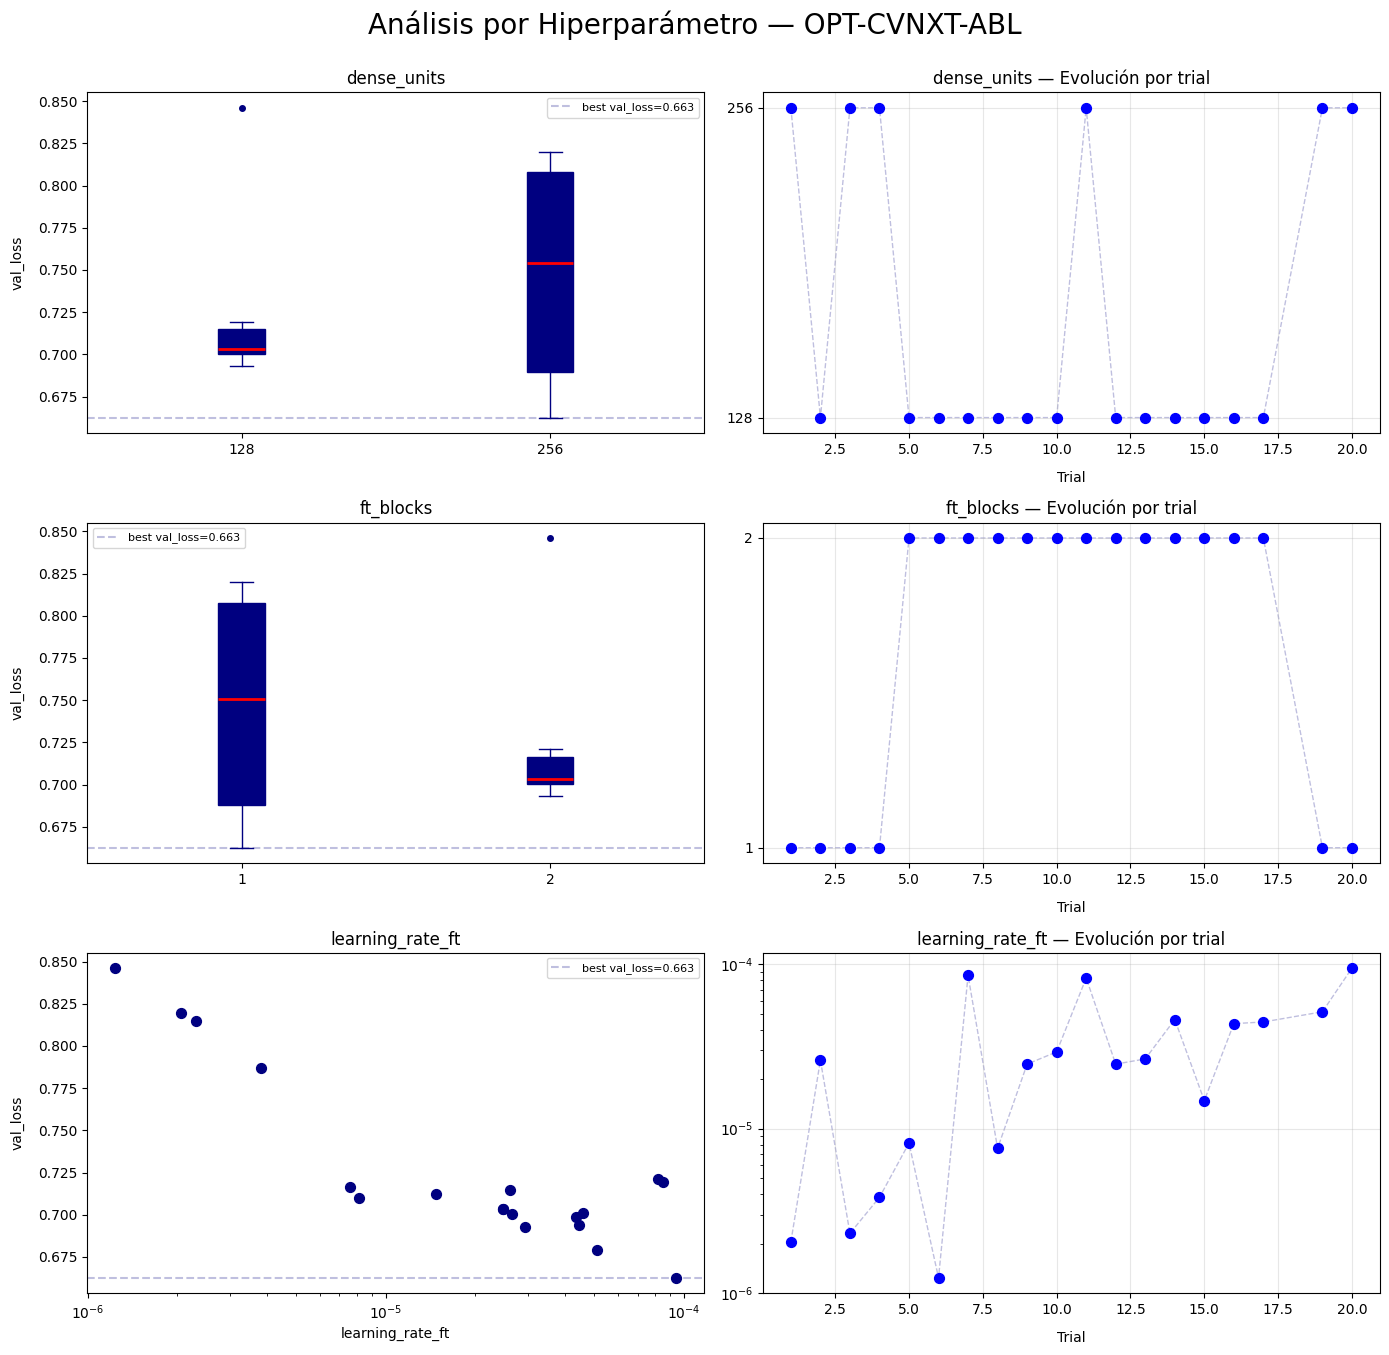

In [15]:
df_complete = df_trials[df_trials['state'] == 'COMPLETE'].copy()
df_complete['number'] = df_complete.index

n_params = len(param_cols)
fig, axes = plt.subplots(n_params, 2, figsize=(14, 4.5 * n_params))
if n_params == 1:
    axes = axes.reshape(1, 2)

for i, param in enumerate(param_cols):
    ax_left  = axes[i, 0]
    ax_right = axes[i, 1]

    is_cat = df_complete[param].dtype == object or df_complete[param].nunique() <= 4

    if is_cat:
        groups = sorted(df_complete[param].dropna().unique())
        data   = [df_complete[df_complete[param] == g]['value'].values for g in groups]
        ax_left.boxplot(
            data, labels=[str(g) for g in groups], patch_artist=True,
            boxprops    = dict(facecolor='navy', color='navy'),
            medianprops = dict(color='red', linewidth=2),
            whiskerprops= dict(color='navy'),
            capprops    = dict(color='navy'),
            flierprops  = dict(markerfacecolor='navy', markeredgecolor='navy', marker='o', markersize=4),
        )
    else:
        ax_left.scatter(df_complete[param], df_complete['value'], color='navy', s=50)
        if param == 'learning_rate_ft':
            ax_left.set_xscale('log')
        ax_left.set_xlabel(param)

    ax_left.axhline(study.best_value, color='navy', linestyle='--', alpha=0.25, linewidth=1.5,
                    label=f'best val_loss={study.best_value:.3f}')
    ax_left.set_ylabel('val_loss', labelpad=10)
    ax_left.set_title(param)
    ax_left.legend(fontsize=8)

    df_sorted = df_complete.sort_values('number')
    if is_cat:
        cats    = sorted(df_complete[param].dropna().unique())
        cat_map = {c: j for j, c in enumerate(cats)}
        y_vals  = df_sorted[param].map(cat_map)
        ax_right.plot(df_sorted['number'], y_vals, color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], y_vals, color='blue', s=50, zorder=2)
        ax_right.set_yticks(range(len(cats)))
        ax_right.set_yticklabels([str(c) for c in cats])
    else:
        ax_right.plot(df_sorted['number'], df_sorted[param], color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], df_sorted[param], color='blue', s=50, zorder=2)
        if param == 'learning_rate_ft':
            ax_right.set_yscale('log')

    ax_right.set_xlabel('Trial', labelpad=10)
    ax_right.set_title(f'{param} — Evolución por trial')
    ax_right.grid(True, alpha=0.3)

plt.suptitle(f'Análisis por Hiperparámetro — {EXPERIMENT_NAME}', fontsize=20, y=1)
plt.tight_layout()
plt.show()

### **Combinación de Hiperparámetros**

In [16]:
try:
    import plotly
    fig = optuna.visualization.plot_parallel_coordinate(study)
    fig.update_layout(title=f'Combinación de Hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado')

In [17]:
df_ranked = df_trials[df_trials['state'].isin(['COMPLETE', 'PRUNED'])].sort_values('value')
display(df_ranked.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,dense_units,ft_blocks,learning_rate_ft
trial,,,,,,,,,
20,0.6626,COMPLETE,12/08 - 16:34,12/08 - 16:37,00:02:56,45.000000,256,1,9.45e-05
19,0.6789,COMPLETE,12/08 - 16:28,12/08 - 16:34,00:05:38,93.000000,256,1,5.13e-05
10,0.6930,COMPLETE,12/08 - 13:59,12/08 - 14:04,00:04:35,49.000000,128,2,2.93e-05
17,0.6941,COMPLETE,12/08 - 16:23,12/08 - 16:26,00:03:25,45.000000,128,2,4.45e-05
16,0.6988,COMPLETE,12/08 - 16:20,12/08 - 16:23,00:03:09,42.000000,128,2,4.35e-05
13,0.7003,COMPLETE,12/08 - 16:08,12/08 - 16:12,00:03:35,49.000000,128,2,2.65e-05
14,0.7013,COMPLETE,12/08 - 16:12,12/08 - 16:15,00:03:04,42.000000,128,2,4.60e-05
12,0.7034,COMPLETE,12/08 - 16:08,12/08 - 16:08,00:00:00,-,128,2,2.47e-05
9,0.7034,COMPLETE,12/08 - 13:55,12/08 - 13:59,00:04:22,49.000000,128,2,2.47e-05
